# M01 Overview | The Three Questions of Quantizing a Model

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/en/m01_hello_pt2e/00_overview.ipynb)

This chapter quantizes a model to int8 for the first time. Before memorizing any API, let's see what quantization has to decide
and where PT2E puts those decisions on the graph. The next three notebooks (M01-1 to M01-3) verify each point hands-on.


In [1]:
#| include: false
# When running on Google Colab: download the course code and install the packages (takes a few minutes the first time).
# When running on your own machine (see the README for the environment), this cell does nothing.
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # so the notebook can import this course's common/
    os.chdir(f"{repo}/en/m01_hello_pt2e")

In [2]:
#| echo: false
import copy

import torch

from common.graph_utils import observer_nodes
from common.models import get_model
from common.pt2e import convert_pt2e, export_module, get_xnnpack_quantizer, prepare_pt2e, quiet
from common.viz import draw, draw_stages, table

quiet()
_ = torch.manual_seed(0)

## Why Quantize, and What Quantization Has to Decide

Replacing fp32 operations with int8 cuts the memory taken by weights and activations to a quarter,
and int8 multiply-accumulate on phones, MCUs, and NPUs is usually much faster than fp32, and uses less power.

The price: the values of an fp32 tensor must be mapped onto integers with only 256 levels.
Every tensor to be quantized needs a mapping rule (as we will see, two numbers: scale and zero point).
A model has dozens or hundreds of tensors, so there are three questions to answer:

1. **Which tensors get quantized?** Not every edge needs it. For example, when a conv is followed directly by a relu, the value in between does not need to be stored as int8.
2. **What are each tensor's scale and zero point?** That depends on the tensor's actual value range, which you only know by looking at data.
3. **How is the result handed to the backend?** The things that finally run int8 kernels, such as XNNPACK and ONNX Runtime, must be able to read it.

PT2E (PyTorch 2 Export quantization) answers: first turn the model into a graph with `torch.export`, then solve all three questions on that graph.

| Question | What PT2E does | How it looks on the graph |
|---|---|---|
| Which tensors to quantize | The **Quantizer** puts annotations on nodes | No new nodes; written in `node.meta` |
| What scale / zero point | **Observers** record value ranges during calibration | Observer nodes appear on edges |
| How to hand over to the backend | Replace observers with **quantize / dequantize** | Each edge becomes a q → dq pair of nodes |

This graph is a `torch.fx` `GraphModule`. If terms like node and graph are unfamiliar,
read "[Some Basics of PyTorch FX Graph / Node](https://bobondemon.github.io/2025/07/29/%E7%AD%86%E8%A8%98-PyTorch-FX-%E7%9A%84-Graph-Node-%E4%B8%80%E4%BA%9B%E5%9F%BA%E7%A4%8E%E6%A6%82%E5%BF%B5/) (in Chinese)" first,
or this project's M00.


## The Four Steps of PT2E

In code, these three things are split into four steps, each an API call. The quantizer is passed in at step 2:

| Step | API | What it does to the graph | Which question it answers |
|---|---|---|---|
| 1. export | `torch.export.export` | Turns an `nn.Module` into an fx graph of ATen ops | (gets the graph ready to edit) |
| 2. prepare | `prepare_pt2e(graph, quantizer)` | Inserts observers on the edges to quantize, following the quantizer's annotations | Which tensors to quantize |
| 3. calibrate | Call the graph directly | Feed representative data; observers record value ranges; the graph itself is unchanged | What scale / zero point |
| 4. convert | `convert_pt2e(graph)` | Replaces observers with quantize / dequantize nodes | How to hand over to the backend |

Of the four steps, only prepare and convert change the graph. M01-1 walks through all four on a trained model.


## An Example First: conv → relu

The smallest example: a conv followed by a relu. The figure below shows the same graph after export, prepare, and convert (calibrate does not change the graph, it only updates the statistics inside the observers, so it is not drawn separately). The first row is export and prepare, the second row is convert:

- **export**: just `conv2d` and `relu`; the weight is written under the conv, inside `‹…›`.
- **prepare**: the quantizer marked three places to quantize: the input `x`, the conv's weight, and the relu's output. `prepare_pt2e` inserts one observer at each (green boxes).
  There is **no** observer between the conv and the relu.
- **convert**: after calibration, each observer is replaced by a quantize → dequantize pair, labeled with the computed scale and zero point.
  The weight is already stored as an int8 constant, so only a dequantize remains.


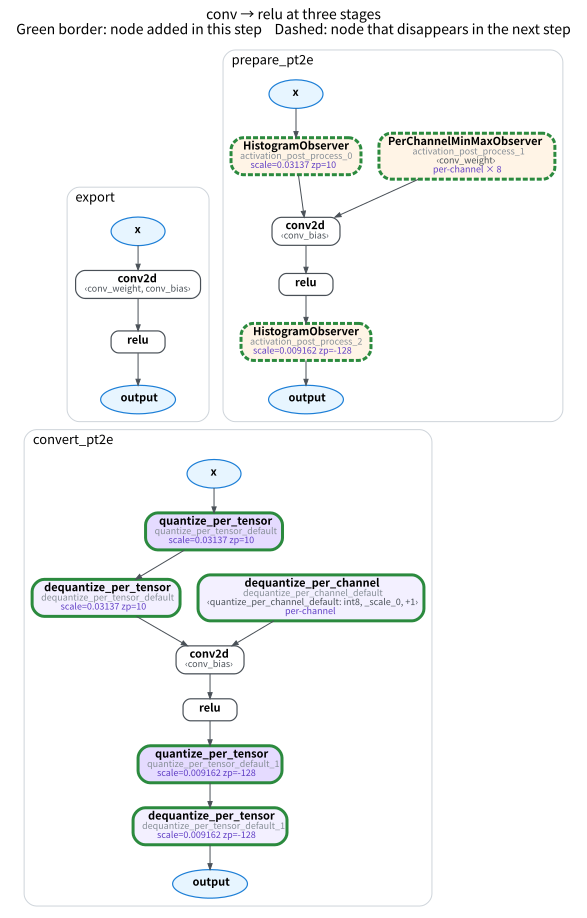

In [3]:
#| echo: false
model = get_model("conv_relu").eval()
ex = (torch.randn(4, 3, 16, 16),)
gm = export_module(model, ex)
quantizer, _ = get_xnnpack_quantizer(is_per_channel=True)
prepared = prepare_pt2e(copy.deepcopy(gm), quantizer)
with torch.no_grad():
    for _ in range(8):
        prepared(torch.randn(4, 3, 16, 16))
converted = convert_pt2e(copy.deepcopy(prepared))
assert len(observer_nodes(prepared)) == 3
draw_stages([(gm, "export"), (prepared, "prepare_pt2e"), (converted, "convert_pt2e")],
            title="conv → relu at three stages")

This figure already answers all three questions: the annotations decide **where** observers go; after seeing data, the observers decide **scale / zero point**;
and convert writes the result as **q/dq**, which the backend can read. Next, let's define each term used so far.

## Definitions

### Affine quantization: scale and zero point

The rule that maps a real number $x$ to an integer $q$ is:

$$
q = \mathrm{clamp}\Big(\mathrm{round}\big(\tfrac{x}{s}\big) + z,\ q_{\min},\ q_{\max}\Big) \tag{1}
$$

Conversely, the real number represented by an integer $q$ is:

$$
\hat{x} = s\,(q - z) \tag{2}
$$

- $s$ (**scale**): how much real value one integer step represents; a positive fp32.
- $z$ (**zero point**): which integer the real number 0 maps to. With it, 0 is always exactly representable (zero padding and the many zeros in relu outputs are not distorted).
- $[q_{\min}, q_{\max}]$: the integer range. For int8 activations it is $[-128, 127]$.

Quantize then dequantize, and the difference between $\hat{x}$ and $x$ is the **quantization error**. As long as $x$ falls inside the representable range, the error is at most half a step:
$|x - \hat{x}| \le s/2$. Values outside the range are clamped, and then the error is unbounded.
So choosing $s$ is a trade-off: a wide range clamps less but makes each step coarser; a narrow range gives finer steps but clamps more easily.

### Observer: computing $s$ and $z$ from the value range

An **observer** is a small module inserted on an edge of the graph: in forward it returns its input unchanged, and records the values it has seen along the way.
The simplest, `MinMaxObserver`, records only the minimum and maximum, then expands the range to include 0:
$x'_{\min} = \min(x_{\min}, 0)$, $x'_{\max} = \max(x_{\max}, 0)$, and then

$$
s = \frac{x'_{\max} - x'_{\min}}{q_{\max} - q_{\min}}, \qquad
z = q_{\min} - \mathrm{round}\Big(\frac{x'_{\min}}{s}\Big) \tag{3}
$$

Weights usually use **symmetric** quantization: $z = 0$ is fixed and the integer range is $[-127, 127]$, so $s = \max|x| / 127$.
Add **per-channel** on top: each output channel of a conv gets its own $s$.

Below we compute this with torchao's observers and compare against the hand calculation from Eq. (3) and the symmetric formula:


In [4]:
from common.pt2e import MinMaxObserver, PerChannelMinMaxObserver

x = torch.randn(1000) * 2 + 0.5
obs = MinMaxObserver(dtype=torch.int8, quant_min=-128, quant_max=127)
obs(x)
s, z = obs.calculate_qparams()
x_min, x_max = min(x.min().item(), 0.0), max(x.max().item(), 0.0)
s_hand = (x_max - x_min) / 255
z_hand = -128 - round(x_min / s_hand)

w = torch.randn(8, 3, 3, 3)
w_obs = PerChannelMinMaxObserver(ch_axis=0, dtype=torch.int8, quant_min=-127, quant_max=127,
                                 qscheme=torch.per_channel_symmetric)
w_obs(w)
w_s, w_z = w_obs.calculate_qparams()

assert torch.isclose(s, torch.tensor(s_hand)) and int(z) == z_hand
assert torch.allclose(w_s, w.abs().amax(dim=(1, 2, 3)) / 127) and not w_z.any()
table([["activation (MinMaxObserver)", f"s={float(s):.5f}, z={int(z)}", f"s={s_hand:.5f}, z={z_hand}"],
       ["weight (per-channel symmetric, channel 0)", f"s={float(w_s[0]):.5f}, z={int(w_z[0])}",
        f"s={float(w[0].abs().max() / 127):.5f}, z=0"]],
      ["", "from observer", "by formula"])

,from observer,by formula
activation (MinMaxObserver),"s=0.05283, z=-7","s=0.05283, z=-7"
"weight (per-channel symmetric, channel 0)","s=0.01301, z=0","s=0.01301, z=0"


The XNNPACKQuantizer used in this project defaults to `HistogramObserver` for activations (this is a quantizer-config choice; another quantizer may differ). It does not take min/max directly,
but picks the range that minimizes quantization error (M02 covers this in detail); once a range is chosen, $s$ and $z$ are computed the same way as Eq. (3).

### Quantizer and annotation

The **Quantizer** is an object supplied by the backend that does exactly one thing: walk the whole graph and write **annotations** on the nodes to be quantized,
for example "conv's input 0 uses int8 per-tensor with HistogramObserver; the weight uses int8 per-channel symmetric".
It does not edit the graph; `prepare_pt2e` reads the annotations and inserts observers.
Why does the backend write them? Because "which ops can be fused and which quantization schemes are supported" is determined by the backend's kernels.

### quantize / dequantize and the Q/DQ graph

`convert_pt2e` replaces each observer with two nodes: `quantize_per_tensor` (Eq. 1, fp32 → int8)
and `dequantize_per_tensor` (Eq. 2, int8 → fp32), with $s$ and $z$ baked into the node's arguments.
The converted graph is called a **Q/DQ graph**: every op is preceded by a dq and followed by a q, and the op itself is still an fp32 computation.
The figure below labels tensor types on the edges (edges with only a shape are float32):


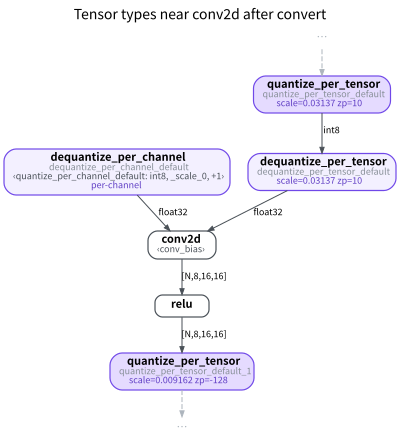

In [5]:
#| echo: false
draw(converted, focus=["conv2d"], hops=2, show_shapes=True, title="Tensor types near conv2d after convert")

The output of q is int8, but dq turns it back into fp32 before handing it to conv2d. So a Q/DQ graph is **not faster**;
it only simulates int8 numerically: every q → dq snaps the value to the nearest step.

So how does the backend use it? Take conv as an example. Both the input and the weight take the form of Eq. (2) (the weight's $z_w = 0$):

$$
\sum_i \hat{w}_i \hat{x}_i = \sum_i s_w q_{w,i} \cdot s_x (q_{x,i} - z_x)
= s_w s_x \sum_i q_{w,i} (q_{x,i} - z_x) \tag{4}
$$

The sum on the right is only integer multiply-accumulate, which can be done as int8 × int8 → int32 accumulation; finally multiply by $s_w s_x$ and quantize back to int8 using the output's $s_y, z_y$.
So the backend only has to recognize the "dq → conv → q" pattern in the graph and replace it with an int8 conv kernel;
all the $s$ and $z$ it needs are written on the q/dq nodes. (How bias and relu get folded in is a backend detail; see M07 and M08.)

## Verify in Code: Quantization Error Is at Most Half a Step

Do one q → dq with the same ops that convert inserts into the graph (`torch.ops.quantized_decomposed`):


In [6]:
s, z = 0.02, -3
x = torch.linspace(-4, 4, 20001)  # representable range is about [-2.5, 2.6]; both ends deliberately exceed it
q = torch.ops.quantized_decomposed.quantize_per_tensor(x, s, z, -128, 127, torch.int8)
x_hat = torch.ops.quantized_decomposed.dequantize_per_tensor(q, s, z, -128, 127, torch.int8)

in_range = (x >= s * (-128 - z)) & (x <= s * (127 - z))
err = (x - x_hat).abs()
print(f"q dtype: {q.dtype}, integer range [{int(q.min())}, {int(q.max())}]")
print(f"Max error inside the range {float(err[in_range].max()):.5f} (s/2 = {s / 2})")
print(f"Max error outside the range (clamped) {float(err[~in_range].max()):.3f}")
assert err[in_range].max() <= s / 2 + 1e-6

q dtype: torch.int8, integer range [-128, 127]
Max error inside the range 0.01000 (s/2 = 0.01)
Max error outside the range (clamped) 1.500


## Summary and Chapter Map

- Quantization answers three questions: which tensors to quantize, each tensor's $s$ and $z$, and how to hand over to the backend.
- PT2E answers them in order on the `torch.export` graph: Quantizer annotation → observer calibration → convert into a Q/DQ graph.
- A Q/DQ graph is only a numerical simulation; the real int8 computation is the kernel the backend swaps in after recognizing dq → op → q.

| notebook | Question it answers |
|---|---|
| [M01-1 Minimal PTQ](01_minimal_ptq.ipynb) | The four steps end to end: how the graph changes at each step and how much accuracy drops |
| [M01-2 What prepare / convert change](02_graph_diff.ipynb) | Which edges observers sit on, how skip connections are handled, which ops the quantizer actually covers |
| [M01-3 The QuantizationConfig switches](03_config_matrix.ipynb) | What per-channel, QAT, and dynamic each change; when per-channel matters |

What this chapter deliberately skips: observer kinds and fake quant (M02), how a quantizer writes annotations (M03), how BN folds into conv (M04),
and how a backend turns a Q/DQ graph into int8 kernels (from M07 on).

## References

- Official PyTorch tutorials: [PyTorch 2 Export Post Training Quantization](https://docs.pytorch.org/ao/stable/pt2e_quantization/pt2e_quant_ptq.html),
  [How to Write a Quantizer for PyTorch 2 Export Quantization](https://docs.pytorch.org/ao/stable/pt2e_quantization/pt2e_quantizer.html)
- torchao source: [`torchao/quantization/pt2e/`](https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) (this project uses torchao 0.18)
- B. Jacob et al., [Quantization and Training of Neural Networks for Efficient Integer-Arithmetic-Only Inference](https://arxiv.org/abs/1712.05877), CVPR 2018: the affine quantization and integer arithmetic behind Eqs. (1)-(4)
- R. Krishnamoorthi, [Quantizing deep convolutional networks for efficient inference: A whitepaper](https://arxiv.org/abs/1806.08342), 2018: per-channel, symmetric vs. asymmetric comparison
- [Some Basics of PyTorch FX Graph / Node](https://bobondemon.github.io/2025/07/29/%E7%AD%86%E8%A8%98-PyTorch-FX-%E7%9A%84-Graph-Node-%E4%B8%80%E4%BA%9B%E5%9F%BA%E7%A4%8E%E6%A6%82%E5%BF%B5/) (in Chinese): nodes and graphs in fx
- [Things About Quantization](https://bobondemon.github.io/2020/10/03/Quantization-%E7%9A%84%E9%82%A3%E4%BA%9B%E4%BA%8B/) (in Chinese): derivation of the affine quantization formulas and integer-only arithmetic; it can serve as a Chinese reading guide to Jacob et al. above. The second half covers PyTorch 1.7 eager-mode QAT (`QuantStub`, `fuse_modules`, `qconfig`), the old API before PT2E, which you can compare against what PT2E changed
